# Model A: milling dose Bayesian optimization

The model targets a number-weighted particle D50 of 200 nm using a single-task Gaussian process with a scaled Matérn 2.5 kernel, log10(D50) output, and learned observation noise. The next dose maximizes noisy expected improvement in negative squared log-distance to 200 nm.

Sample-specific cycle counts and energies come from `Documentation/00_Package_Summary.xlsx`, sheet `Conditions`, joined by full sample name. The third filename component identifies the sample. Nominal energy is 1.29 kJ/g per cycle at 900 rpm. The dataset contains 14 samples and 58 images. Active milling duration per cycle is unspecified.

Data-rights labels and source locations accompany the processed data. Source notices are available in `Data/milling_summary_processed.notices.txt` and `Model/results/DATA_NOTICES.txt`.


In [40]:
from pathlib import Path
import importlib.util
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import botorch
from IPython.display import display
from botorch.models import SingleTaskGP
from botorch.models.transforms.outcome import Standardize
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood
from gpytorch.kernels import ScaleKernel, MaternKernel, RBFKernel
from botorch.acquisition.logei import qLogNoisyExpectedImprovement
from botorch.acquisition.objective import GenericMCObjective
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.optim import optimize_acqf, optimize_acqf_discrete

SEED = 20261027
DTYPE = torch.float64
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
# Locate the main model from the notebook folder or project root.
MODEL_DIR = next((q.resolve() for q in [Path.cwd(), Path.cwd()/'Model']
                  if (q/'Data_Preprocessing.py').is_file() and (q/'BO_Model_A.ipynb').is_file()), None)
if MODEL_DIR is None:
    raise FileNotFoundError('Run from Model/ or the Genesis_Project root.')
spec = importlib.util.spec_from_file_location('milling_preprocessing', MODEL_DIR/'Data_Preprocessing.py')
dp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(dp)
PROJECT_ROOT = dp.find_project_root(MODEL_DIR)
RESULTS = MODEL_DIR/'results'
RESULTS.mkdir(exist_ok=True)
TARGET_NM = 200.0
TOLERANCE_NM = 20.0  # Tolerance used for probability reporting.
ENERGY_PER_CYCLE = 1.29
NET_MINUTES_PER_CYCLE = None  # Unknown; cooling/rest time must be excluded.
# Whole-cycle candidate domain, bounded by the observed cycle range.
# Candidate settings use integer cycle counts.
CYCLE_BOUNDS = (0, 99)
ENERGY_BOUNDS = (0.0, CYCLE_BOUNDS[1]*ENERGY_PER_CYCLE)
MC_SAMPLES = 4096
print(f'PyTorch {torch.__version__}; BoTorch {botorch.__version__}')
summary_df = dp.process_pipeline(
    PROJECT_ROOT/'Data/raw_data', PROJECT_ROOT/'Data/milling_summary_processed.csv',
    net_minutes_per_cycle=NET_MINUTES_PER_CYCLE)
(RESULTS/'DATA_NOTICES.txt').write_text((PROJECT_ROOT/'Data/milling_summary_processed.notices.txt').read_text())
if not summary_df.RPM.eq(900).all():
    raise ValueError('Reconfigure the cycle-to-energy candidate grid for other speeds.')
if not summary_df.E_cum_kJ_g.between(*ENERGY_BOUNDS).all():
    raise ValueError('Observed energy outside declared design bounds.')
display(summary_df[['Condition','Sample_ID','Cycle_Count','E_cum_kJ_g','Image_Count','D50_nm','Magnification']])

PyTorch 2.14.0; BoTorch 0.18.1
11,954 particles -> 9,993 valid particles; 14 samples, 11 energy doses
Cycle counts and doses joined by full sample name from Conditions sheet.


,Condition,Sample_ID,Cycle_Count,E_cum_kJ_g,Image_Count,D50_nm,Magnification
0,261006_900_1_5000,1.0,0,0.00,5,1126.415929,5000
1,261013_900_1_10000,1.0,2,2.58,5,563.626379,10000
2,261013_900_2_20000,2.0,4,5.16,5,264.921716,20000
3,261006_900_2_20000,2.0,5,6.45,5,263.360456,20000
4,261013_900_3_20000,3.0,6,7.74,5,265.070849,20000
5,261013_900_4_20000,4.0,8,10.32,5,243.351954,20000
6,261006_900_3_20000,3.0,10,12.90,5,252.310681,20000
7,261013_900_5_20000,5.0,10,12.90,5,239.116590,20000
8,261006_900_4_30000,4.0,15,19.35,5,195.528348,30000
9,261006_900_5_30000,5.0,20,25.80,5,206.814460,30000


## Surrogate and validation

The main model uses a Matérn 2.5 covariance kernel and log10(D50) output. Outcome standardization is fitted within each training fold. Posterior outputs are expressed in log10(nm), and inputs are scaled over 0–127.71 kJ/g.

Validation reports pooled out-of-fold R² on log10 and nm scales, a training-fold mean baseline, prediction-interval coverage, and per-condition errors. An additional positive-dose scoring diagnostic evaluates the effect of extrapolation to the zero-dose sample. All observations are included in the final model. Exponentiated log means are medians in nm.

The validation schemes hold out one condition, one energy dose, or one batch date. Date serves as a batch proxy. The package summary specifies identical milling conditions apart from cycle count. SEM magnification varies across samples. Prediction intervals include observation noise and exclude hyperparameter uncertainty.


In [41]:
energy = summary_df.E_cum_kJ_g.to_numpy()
y_log = np.log10(summary_df.D50_nm.to_numpy())
energy_span = ENERGY_BOUNDS[1]-ENERGY_BOUNDS[0]
X = torch.tensor(((energy-ENERGY_BOUNDS[0])/energy_span)[:,None], dtype=DTYPE)
Y = torch.tensor(y_log[:,None], dtype=DTYPE)

def fit_model(x, y, kernel='Matern25'):
    base = {'Matern25': lambda: MaternKernel(nu=2.5),
            'Matern15': lambda: MaternKernel(nu=1.5), 'RBF': RBFKernel}[kernel]()
    model = SingleTaskGP(x, y, covar_module=ScaleKernel(base), outcome_transform=Standardize(m=1))
    fit_gpytorch_mll(ExactMarginalLogLikelihood(model.likelihood, model))
    model.eval()
    return model

def r2(actual, predicted):
    denominator = np.sum((actual-np.mean(actual))**2)
    return np.nan if denominator <= 0 else 1-np.sum((actual-predicted)**2)/denominator

def validate(kernel, labels, name, save=True):
    labels = np.asarray(labels)
    pred, var, baseline = [np.full(len(Y),np.nan) for _ in range(3)]
    for label in pd.unique(labels):
        test = labels == label
        model = fit_model(X[~test],Y[~test],kernel)
        with torch.no_grad():
            posterior = model.posterior(X[test], observation_noise=True)
            pred[test] = posterior.mean.squeeze(-1).numpy()
            var[test] = posterior.variance.squeeze(-1).numpy()
        baseline[test] = y_log[~test].mean()
    sd = np.sqrt(var)
    details = summary_df[['Condition','Cycle_Count','E_cum_kJ_g','D50_nm']].copy()
    details['Predicted_log10_D50'] = pred
    details['Predicted_median_nm'] = 10**pred
    details['Prediction_lower_nm'] = 10**(pred-1.96*sd)
    details['Prediction_upper_nm'] = 10**(pred+1.96*sd)
    se = (y_log-pred)**2
    details['Squared_log_error_share'] = se/se.sum() if se.sum()>0 else 0
    if save: details.to_csv(RESULTS/f'validation_{kernel}_{name}.csv',index=False)
    positive = energy>0
    metrics = dict(Kernel=kernel, Split=name, R2_log10=r2(y_log,pred),
                   Baseline_R2_log10=r2(y_log,baseline), RMSE_log10=np.sqrt(se.mean()),
                   R2_nm_median=r2(10**y_log,10**pred), MAE_nm_median=np.abs(10**y_log-10**pred).mean(),
                   Coverage95=np.mean(np.abs(y_log-pred)<=1.96*sd),
                   R2_log10_positive_dose_scoring_only=r2(y_log[positive],pred[positive]))
    return metrics, details

validation_rows=[]
for split, labels in [('condition',np.arange(len(Y))),('energy',energy),('batch_date',summary_df.Batch_Date)]:
    metrics, details = validate('Matern25',labels,split)
    validation_rows.append(metrics)
    print(split, 'R²(log10) =', round(metrics['R2_log10'],4))
validation=pd.DataFrame(validation_rows)
validation.to_csv(RESULTS/'validation_metrics.csv',index=False)
display(validation)
gp=fit_model(X,Y)

condition R²(log10) = 0.6104
energy R²(log10) = 0.2449
batch_date R²(log10) = 0.4209


,Kernel,Split,R2_log10,Baseline_R2_log10,RMSE_log10,R2_nm_median,MAE_nm_median,Coverage95,R2_log10_positive_dose_scoring_only
0,Matern25,condition,0.610364,-0.159763,0.139073,0.321114,76.874316,0.785714,0.834127
1,Matern25,energy,0.244909,-0.242520,0.193604,0.238583,108.823786,0.857143,-0.173430
2,Matern25,batch_date,0.420916,-0.141341,0.169545,0.164875,92.297257,0.785714,0.721542


## Particle-size curve and uncertainty

D10–D90 describes the particle-size distribution within each condition. Each condition contributes one GP observation. The model estimates a shared noise variance in log space. Image-level sampling variation and milling variability are not modeled separately.


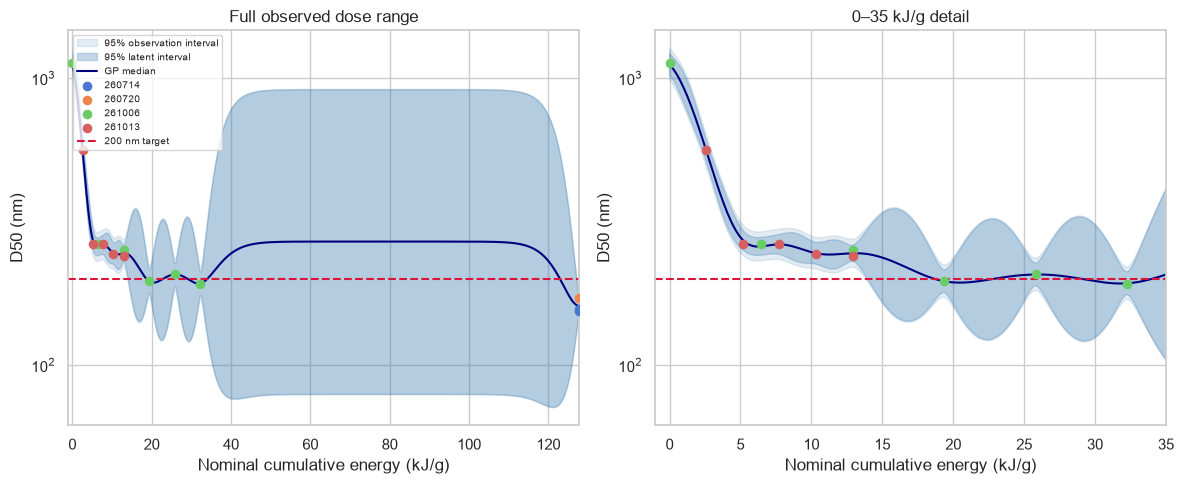

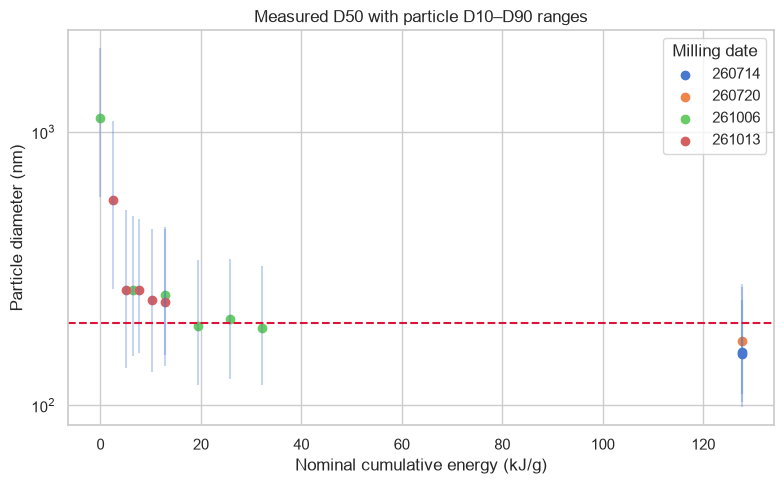

In [42]:
grid_energy=np.linspace(*ENERGY_BOUNDS,1001)
grid_x=torch.tensor(((grid_energy-ENERGY_BOUNDS[0])/energy_span)[:,None],dtype=DTYPE)
with torch.no_grad():
    latent=gp.posterior(grid_x)
    observed=gp.posterior(grid_x,observation_noise=True)
    mu=latent.mean.squeeze(-1).numpy()
    sd_latent=latent.variance.squeeze(-1).sqrt().numpy()
    sd_observed=observed.variance.squeeze(-1).sqrt().numpy()
predictions=pd.DataFrame(dict(E_cum_kJ_g=grid_energy,Median_D50_nm=10**mu,
    Expected_observation_D50_nm=np.exp(np.log(10)*mu+0.5*np.log(10)**2*sd_observed**2),
    Latent_lower_nm=10**(mu-1.96*sd_latent),Latent_upper_nm=10**(mu+1.96*sd_latent),
    Prediction_lower_nm=10**(mu-1.96*sd_observed),Prediction_upper_nm=10**(mu+1.96*sd_observed)))
predictions.to_csv(RESULTS/'surrogate_predictions.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,upper in zip(axes,[ENERGY_BOUNDS[1],35]):
    ax.fill_between(grid_energy,predictions.Prediction_lower_nm,predictions.Prediction_upper_nm,
                    alpha=.15,color='steelblue',label='95% observation interval')
    ax.fill_between(grid_energy,predictions.Latent_lower_nm,predictions.Latent_upper_nm,
                    alpha=.3,color='steelblue',label='95% latent interval')
    ax.plot(grid_energy,predictions.Median_D50_nm,color='navy',label='GP median')
    for date,g in summary_df.groupby('Batch_Date'):
        ax.scatter(g.E_cum_kJ_g,g.D50_nm,s=35,label=str(date),zorder=5)
    ax.axhline(TARGET_NM,color='crimson',linestyle='--',label='200 nm target')
    ax.set(xlim=(-1,upper),xlabel='Nominal cumulative energy (kJ/g)',ylabel='D50 (nm)',yscale='log')
axes[0].set_title('Full observed dose range')
axes[1].set_title('0–35 kJ/g detail')
axes[0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(MODEL_DIR/'gp_model_fit.png',dpi=180)
plt.show()
fig,ax=plt.subplots(figsize=(8,5))
for date,g in summary_df.groupby('Batch_Date'):
    ax.scatter(g.E_cum_kJ_g,g.D50_nm,label=str(date))
    ax.vlines(g.E_cum_kJ_g,g.D10_nm,g.D90_nm,alpha=.3)
ax.axhline(TARGET_NM,color='crimson',linestyle='--')
ax.set(xlabel='Nominal cumulative energy (kJ/g)',ylabel='Particle diameter (nm)',yscale='log',title='Measured D50 with particle D10–D90 ranges')
ax.legend(title='Milling date')
fig.tight_layout()
fig.savefig(MODEL_DIR/'milling_energy_vs_particle_size.png',dpi=180)
plt.show()

## Target-seeking Bayesian optimization

The acquisition objective is `-(log10(D50) - log10(200))²`, evaluated on posterior samples.

The main search evaluates whole cycles from 0 to 99 within the observed dose range. qLogNEI selects a next experiment based on expected improvement in the latent objective. Repeating an observed point has no exact latent improvement over itself, so this acquisition does not explicitly optimize replication. A separate continuous-dose search provides a comparison with the whole-cycle domain.


In [43]:
target_log=float(np.log10(TARGET_NM))
objective=GenericMCObjective(lambda samples,X=None: -(samples.squeeze(-1)-target_log).square())
probe=torch.tensor(np.log10([100.,200.,400.]),dtype=DTYPE).reshape(1,3,1)
assert objective(probe).argmax().item()==1
cycles=np.arange(CYCLE_BOUNDS[0],CYCLE_BOUNDS[1]+1)
choices=torch.tensor(((cycles*ENERGY_PER_CYCLE-ENERGY_BOUNDS[0])/energy_span)[:,None],dtype=DTYPE)

def acquisition(model,seed=SEED,obj=objective):
    return qLogNoisyExpectedImprovement(model=model,X_baseline=torch.unique(X,dim=0),
        objective=obj,sampler=SobolQMCNormalSampler(torch.Size([MC_SAMPLES]),seed=seed),prune_baseline=False)

def describe_candidate(model,candidate):
    dose=float(candidate.item()*energy_span+ENERGY_BOUNDS[0])
    with torch.no_grad():
        posterior=model.posterior(candidate,observation_noise=True)
        mean=posterior.mean.item()
        sd=posterior.variance.sqrt().item()
    normal=torch.distributions.Normal(torch.tensor(mean,dtype=DTYPE),torch.tensor(sd,dtype=DTYPE))
    low,high=np.log10([TARGET_NM-TOLERANCE_NM,TARGET_NM+TOLERANCE_NM])
    probability=float(normal.cdf(torch.tensor(high))-normal.cdf(torch.tensor(low)))
    return dict(E_cum_kJ_g=dose,Cycle_Count=dose/ENERGY_PER_CYCLE,
                Predicted_median_nm=10**mean,Prediction_lower_nm=10**(mean-1.96*sd),
                Prediction_upper_nm=10**(mean+1.96*sd),Model_probability_180_to_220_nm=probability)

acq=acquisition(gp)
candidate,value=optimize_acqf_discrete(acq,q=1,choices=choices,max_batch_size=16)
recommendation=describe_candidate(gp,candidate)
recommendation.update(Kernel='Matern25',Objective='negative_squared_log_distance',
                      Acquisition='qLogNEI',Search='whole_cycles_0_to_99',Seed=SEED,
                      Log_acquisition_value=float(value.item()),RPM=900)
recommendation['Cycle_Count']=int(round(recommendation['Cycle_Count']))
(RESULTS/'recommendation.json').write_text(json.dumps(recommendation,indent=2)+'\n')
pd.DataFrame([recommendation]).to_csv(RESULTS/'recommendation.csv',index=False)
print(f"MAIN BO CANDIDATE: {recommendation['E_cum_kJ_g']:.2f} kJ/g = {recommendation['Cycle_Count']} cycles at 900 rpm")
display(pd.DataFrame([recommendation]).T)
# Evaluate the acquisition over the cycle grid.
with torch.no_grad():
    acquisition_values=torch.cat([acq(chunk.unsqueeze(-2)) for chunk in choices.split(16)]).numpy()
pd.DataFrame(dict(Cycle_Count=cycles,E_cum_kJ_g=cycles*ENERGY_PER_CYCLE,
    Log_acquisition_value=acquisition_values)).to_csv(RESULTS/'acquisition_by_cycle.csv',index=False)
torch.manual_seed(SEED)
continuous,continuous_value=optimize_acqf(acq,bounds=torch.tensor([[0.],[1.]],dtype=DTYPE),q=1,
    num_restarts=20,raw_samples=512,options={'batch_limit':4})
continuous_result=describe_candidate(gp,continuous)
continuous_result['Search']='continuous_energy_comparison_only'
pd.DataFrame([continuous_result]).to_csv(RESULTS/'continuous_candidate.csv',index=False)
print('Continuous comparison:',round(continuous_result['E_cum_kJ_g'],3),'kJ/g')

MAIN BO CANDIDATE: 18.06 kJ/g = 14 cycles at 900 rpm


,0
E_cum_kJ_g,18.06
Cycle_Count,14
Predicted_median_nm,204.628508
Prediction_lower_nm,151.379544
Prediction_upper_nm,276.608221
Model_probability_180_to_220_nm,0.479021
Kernel,Matern25
Objective,negative_squared_log_distance
Acquisition,qLogNEI
Search,whole_cycles_0_to_99


Continuous comparison: 18.885 kJ/g


## Sensitivity to model and objective choices

Sensitivity analysis compares Matérn 2.5, Matérn 1.5, and RBF kernels using the same log output, observations, search domain, and acquisition. Additional comparisons use squared nm-distance and independent Monte Carlo seeds. Model selection is uncertain with 14 observations.

An exploitation comparison minimizes posterior expected squared log-distance to the target. This criterion differs from the improvement-based next-experiment policy.


In [44]:
sensitivity=[]
for kernel in ['Matern25','Matern15','RBF']:
    model=gp if kernel=='Matern25' else fit_model(X,Y,kernel)
    metric=validation_rows[0] if kernel=='Matern25' else validate(kernel,np.arange(len(Y)),'condition')[0]
    a=acq if kernel=='Matern25' else acquisition(model)
    c,v=optimize_acqf_discrete(a,q=1,choices=choices,max_batch_size=16)
    row=describe_candidate(model,c)
    row.update(Kernel=kernel,Objective='log_squared',Seed=SEED,R2_log10=metric['R2_log10'])
    sensitivity.append(row)
# Equal absolute nm deviations have equal loss in this alternative objective.
nm_objective=GenericMCObjective(lambda samples,X=None: -((10**samples.squeeze(-1)-TARGET_NM)/TARGET_NM).square())
for label,seed,obj in [('nm_squared',SEED,nm_objective),('log_squared',SEED+1,objective),('log_squared',SEED+2,objective)]:
    a=acquisition(gp,seed,obj)
    c,v=optimize_acqf_discrete(a,q=1,choices=choices,max_batch_size=16)
    row=describe_candidate(gp,c)
    row.update(Kernel='Matern25',Objective=label,Seed=seed,R2_log10=validation_rows[0]['R2_log10'])
    sensitivity.append(row)
sensitivity=pd.DataFrame(sensitivity)
sensitivity.to_csv(RESULTS/'model_sensitivity.csv',index=False)
display(sensitivity)
with torch.no_grad():
    posterior=gp.posterior(choices)
    loss=(posterior.mean.squeeze(-1)-target_log).square()+posterior.variance.squeeze(-1)
    exploitation=describe_candidate(gp,choices[loss.argmin():loss.argmin()+1])
pd.DataFrame([exploitation]).to_csv(RESULTS/'exploitation_comparison.csv',index=False)
print('Minimum posterior expected squared log-error:',round(exploitation['E_cum_kJ_g'],2),'kJ/g')
print('No milling duration is reported because net minutes per cycle are undocumented.')
print('Check the sparse gap between 32.25 and 127.71 kJ/g and model sensitivity before choosing the next experiment.')

,E_cum_kJ_g,Cycle_Count,Predicted_median_nm,Prediction_lower_nm,Prediction_upper_nm,Model_probability_180_to_220_nm,Kernel,Objective,Seed,R2_log10
0,18.06,14.0,204.628508,151.379544,276.608221,0.479021,Matern25,log_squared,20261027,0.610364
1,18.06,14.0,203.465648,151.707437,272.882270,0.492434,Matern15,log_squared,20261027,0.642253
2,1.29,1.0,281.343794,98.662035,802.277496,0.120993,RBF,log_squared,20261027,0.507425
3,18.06,14.0,204.628508,151.379544,276.608221,0.479021,Matern25,nm_squared,20261027,0.610364
4,18.06,14.0,204.628508,151.379544,276.608221,0.479021,Matern25,log_squared,20261028,0.610364
5,18.06,14.0,204.628508,151.379544,276.608221,0.479021,Matern25,log_squared,20261029,0.610364


Minimum posterior expected squared log-error: 19.35 kJ/g
No milling duration is reported because net minutes per cycle are undocumented.
Check the sparse gap between 32.25 and 127.71 kJ/g and model sensitivity before choosing the next experiment.


## Interpretation

- D50 is number-weighted from segmented SEM particles.
- The final model includes all 14 samples. Images provide within-sample measurements rather than independent milling runs.
- Variation in magnification, one zero-dose sample, limited batch dates, and the gap between 25 and 99 cycles limit generalization and uncertainty calibration.
- The stationary covariance kernels do not impose monotonic particle-size reduction. Recommendations depend on kernel smoothness and the objective definition.
- Recommended cycles represent cumulative milling from the starting material. Nominal dose describes ball energy rather than measured energy absorbed by powder.
